# Lab 1 — Basic Image Operations with OpenCV and Pillow

**CSE-4875: Pattern Recognition & Image Processing** · Department of CSE, IIUC

This notebook runs **locally in VS Code**, not in Google Colab. Everything reads from the
`images/` folder next to this file, so no Drive mounting and no `cv2_imshow`.

**Setup (once, in the VS Code terminal):**

```bash
pip install opencv-python pillow numpy matplotlib
```

Then pick the Python kernel in the top-right corner of VS Code and run the cells in order.

**Folder layout**

```
lab1/
├── Lab_1_Image_Operations_VSCode.ipynb   <- this file
├── make_samples.py                       <- creates the sample images
└── images/
    ├── rgb.jpg          scene with strong red, green and blue areas
    ├── shapes.png       shapes on white, for thresholding and contours
    ├── gradient.png     grey staircase, for Mach bands and quantisation
    ├── lowcontrast.jpg  for histogram equalisation
    ├── dark.jpg         under-exposed, for gamma correction
    ├── noisy.png        salt-and-pepper noise, for the median filter
    ├── text.png         text under uneven light, for adaptive thresholding
    └── logo.png         small logo, for masking
```

Replace any of these with your own photos; only the file names have to match.

## 0. Imports and a display helper

Two rules for this lab:

1. **OpenCV stores colour as BGR, not RGB.** Matplotlib expects RGB. If you forget to
   convert, the sky turns orange. We convert explicitly every time, so the mistake is visible.
2. We display with **matplotlib inside the notebook**. `cv2.imshow` opens a separate desktop
   window; that works on your laptop but blocks the notebook, so it is kept for the last section.

In [43]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont, ImageEnhance, ImageFilter, ImageOps

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)
print("Working directory:", Path.cwd())

OpenCV : 5.0.0
NumPy  : 2.5.4
Working directory: d:\ai ml by ifty\image  processing\week 1


In [44]:
from pathlib import Path

# Since images/ is right inside the week 1 folder along with the notebook:
IMG_DIR = Path("images")

if not IMG_DIR.is_dir() or not any(IMG_DIR.glob("*")):
    print("images/ not found. Run  python make_samples.py  in this folder first.")
else:
    print("Using:", IMG_DIR.resolve())
    for p in sorted(IMG_DIR.iterdir()):
        print("  ", p.name)

Using: D:\ai ml by ifty\image  processing\week 1\images
   dark.jpg
   gradient.png
   logo.png
   lowcontrast.jpg
   noisy.png
   rgb.jpg
   shapes.png
   text.png


In [45]:
# Find the images folder no matter where the kernel was started
IMG_DIR  = Path("image processing/week1/images")
for candidate in [Path.cwd() / "images", Path.cwd().parent / "images", Path("images")]:
    if candidate.is_dir():
        IMG_DIR = candidate.resolve()
        break

if IMG_DIR is None or not any(IMG_DIR.glob("*")):
    print("images/ not found. Run  python make_samples.py  in this folder first.")
else:
    print("Using:", IMG_DIR)
    for p in sorted(IMG_DIR.iterdir()):
        print("  ", p.name)

Using: D:\ai ml by ifty\image  processing\week 1\images
   dark.jpg
   gradient.png
   logo.png
   lowcontrast.jpg
   noisy.png
   rgb.jpg
   shapes.png
   text.png


In [46]:
def show(imgs, titles=None, cols=None, size=3.4, cmap="gray"):
    """Draw one image or a list of images in a row.
    A 2-D array is drawn as greyscale, a 3-D array is assumed to be RGB."""
    if isinstance(imgs, np.ndarray) or isinstance(imgs, Image.Image):
        imgs = [imgs]
    n = len(imgs)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.95))
    axes = np.atleast_1d(axes).ravel()
    for ax, im in zip(axes, imgs):
        arr = np.asarray(im)
        ax.imshow(arr, cmap=cmap if arr.ndim == 2 else None,
                  vmin=0 if arr.ndim == 2 and arr.dtype == np.uint8 else None,
                  vmax=255 if arr.ndim == 2 and arr.dtype == np.uint8 else None)
        ax.axis("off")
    if titles:
        for ax, t in zip(axes, titles):
            ax.set_title(t, fontsize=10)
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def bgr2rgb(img):
    """OpenCV image -> matplotlib-friendly image."""
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("helpers ready")

helpers ready


## 1. Reading and writing an image

`cv2.imread(path, flag)` returns a NumPy array, or **`None`** when the file is missing or the
path is wrong. It does not raise an error. Always check.

| flag | value | meaning |
|---|---|---|
| `cv2.IMREAD_COLOR` | 1 | 3-channel BGR, transparency dropped (default) |
| `cv2.IMREAD_GRAYSCALE` | 0 | single channel |
| `cv2.IMREAD_UNCHANGED` | -1 | keep everything, including an alpha channel |

colour shape: (480, 640, 3) | grey shape: (480, 640)


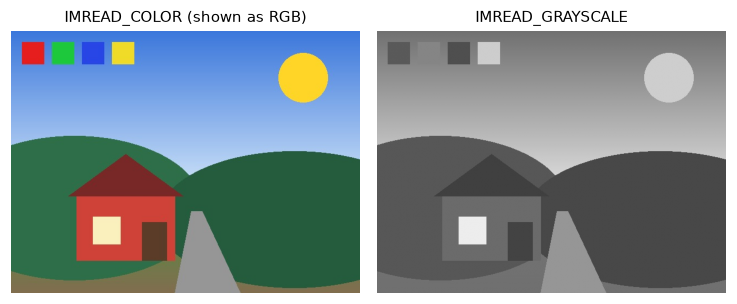

In [47]:
path = str(IMG_DIR / "rgb.jpg")

img_bgr  = cv2.imread(path, cv2.IMREAD_COLOR)
img_gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img_bgr is None:
    raise FileNotFoundError(f"OpenCV could not read {path}")

print("colour shape:", img_bgr.shape, "| grey shape:", img_gray.shape)
show([bgr2rgb(img_bgr), img_gray], ["IMREAD_COLOR (shown as RGB)", "IMREAD_GRAYSCALE"])

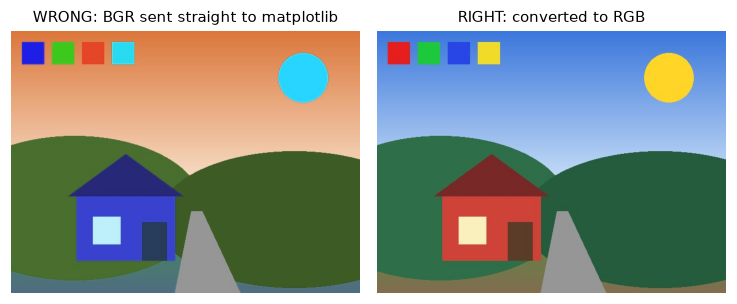

In [48]:
# The classic first mistake: giving matplotlib a BGR array
show([img_bgr, bgr2rgb(img_bgr)],
     ["WRONG: BGR sent straight to matplotlib", "RIGHT: converted to RGB"])

In [49]:
# Writing. cv2.imwrite expects BGR and picks the format from the extension.
out_dir = Path("output")
out_dir.mkdir(exist_ok=True)

cv2.imwrite(str(out_dir / "copy.png"), img_bgr)
cv2.imwrite(str(out_dir / "copy_q30.jpg"), img_bgr, [cv2.IMWRITE_JPEG_QUALITY, 30])
cv2.imwrite(str(out_dir / "copy_q95.jpg"), img_bgr, [cv2.IMWRITE_JPEG_QUALITY, 95])

for f in sorted(out_dir.glob("copy*")):
    print(f"{f.name:14s} {f.stat().st_size/1024:7.1f} KB")

copy.png          85.1 KB
copy_q30.jpg       9.1 KB
copy_q95.jpg      30.1 KB


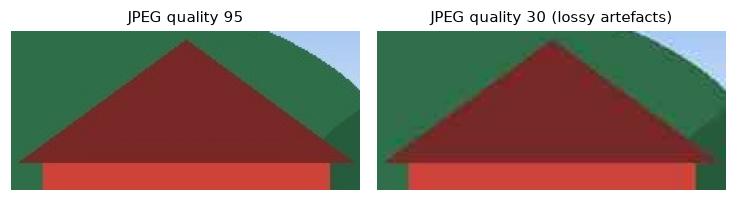

In [50]:
# Same picture at two JPEG qualities. Zoom into the roof edge to see the blocks.
q30 = cv2.imread(str(out_dir / "copy_q30.jpg"))
q95 = cv2.imread(str(out_dir / "copy_q95.jpg"))
show([bgr2rgb(q95)[220:320, 100:320], bgr2rgb(q30)[220:320, 100:320]],
     ["JPEG quality 95", "JPEG quality 30 (lossy artefacts)"])

## 2. Image properties

An image is just a NumPy array of numbers.

* `shape` → `(height, width, channels)`. Height comes **first**.
* `dtype` → almost always `uint8`, so every value is an integer from 0 to 255.
* `size` → total number of values, i.e. height × width × channels.

In [51]:
h, w, c = img_bgr.shape
print("height         :", h)
print("width          :", w)
print("channels       :", c)
print("dtype          :", img_bgr.dtype)
print("total values   :", img_bgr.size)
print("memory (KB)    :", img_bgr.nbytes / 1024)
print("min / max      :", img_bgr.min(), "/", img_bgr.max())
print("mean per B,G,R :", img_bgr.mean(axis=(0, 1)).round(1))
print()
print("one pixel at row 250, col 200 (B, G, R):", img_bgr[250, 200])

height         : 480
width          : 640
channels       : 3
dtype          : uint8
total values   : 921600
memory (KB)    : 900.0
min / max      : 20 / 255
mean per B,G,R : [136.8 127.9  99. ]

one pixel at row 250, col 200 (B, G, R): [ 39  40 120]


## 3. Pixels, slicing and cropping

Indexing is `img[row, col]`, that is `img[y, x]`. A crop is plain NumPy slicing:
`img[y1:y2, x1:x2]`.

Slicing gives a **view**, not a copy. Writing into the slice changes the original image, so use
`.copy()` when you want to keep the original safe.

crop shape: (210, 220, 3)


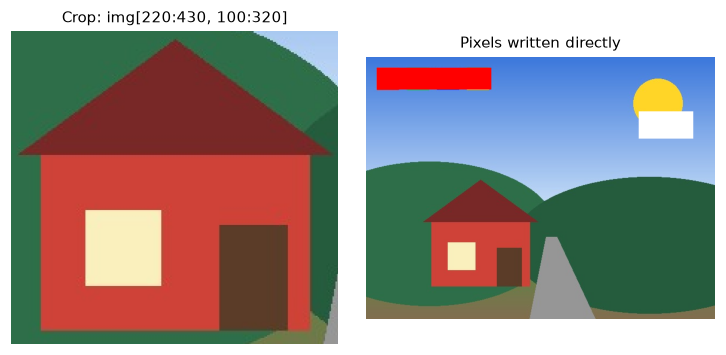

In [52]:
roi = img_bgr[220:430, 100:320]          # the house
print("crop shape:", roi.shape)

edited = img_bgr.copy()
edited[20:60, 20:230] = (0, 0, 255)      # paint a red bar (BGR order!)
edited[100:150, 500:600] = 255           # paint white

show([bgr2rgb(roi), bgr2rgb(edited)], ["Crop: img[220:430, 100:320]", "Pixels written directly"])

## 4. Colour spaces

`cv2.cvtColor(img, flag)` moves an image from one colour space to another.

* **Grey** — one value per pixel. Most classical algorithms start here.
* **HSV** — Hue (which colour, 0–179 in OpenCV), Saturation (how pure), Value (how bright).
  Useful because the colour is separated from the lighting, so colour selection becomes easy.
* **LAB** — L is lightness, a and b carry the colour. Closer to human perception.

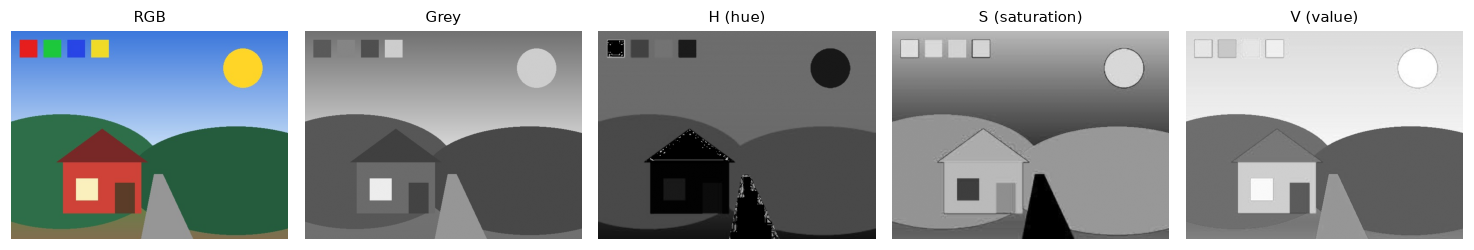

In [53]:
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
hsv  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
lab  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)

show([bgr2rgb(img_bgr), gray, hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]],
     ["RGB", "Grey", "H (hue)", "S (saturation)", "V (value)"], cols=5, size=2.7)

### Picking one colour with `cv2.inRange`

This is the standard way to segment by colour: convert to HSV, give a low and a high bound,
and get a binary mask. Try changing the hue range and re-running.

pixels selected: 115656 of 307200


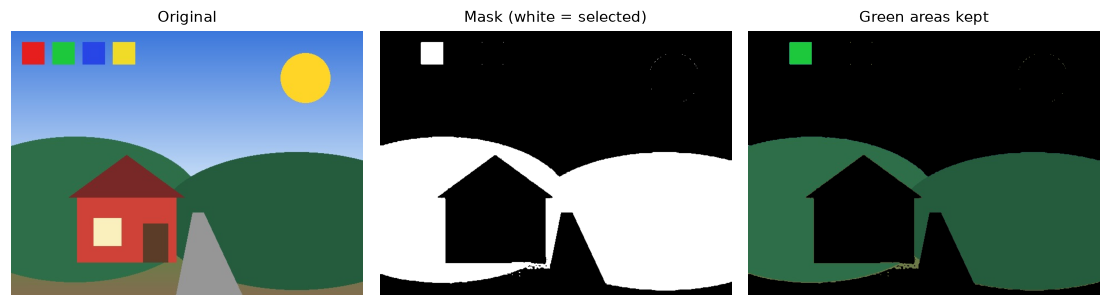

In [54]:
# green range in OpenCV HSV (hue 0-179)
lower = np.array([35,  60,  40])
upper = np.array([85, 255, 255])

mask = cv2.inRange(hsv, lower, upper)
green_only = cv2.bitwise_and(img_bgr, img_bgr, mask=mask)

print("pixels selected:", int(mask.sum() / 255), "of", mask.size)
show([bgr2rgb(img_bgr), mask, bgr2rgb(green_only)],
     ["Original", "Mask (white = selected)", "Green areas kept"])

## 5. Splitting and merging channels

`cv2.split` is slow because it copies. For simple work, NumPy slicing is faster and clearer:
`img[:, :, 0]` is blue, `img[:, :, 1]` is green, `img[:, :, 2]` is red.

A channel on its own is a **greyscale** image. Bright in the red channel means "a lot of red
here", so the red house and the yellow sun both look bright in it.

channel shape: (480, 640) | same as slicing: True


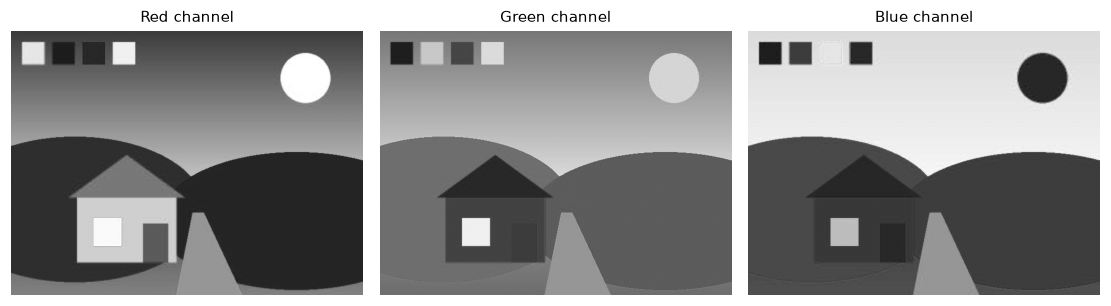

In [55]:
b, g, r = cv2.split(img_bgr)
print("channel shape:", b.shape, "| same as slicing:", np.array_equal(b, img_bgr[:, :, 0]))

show([r, g, b], ["Red channel", "Green channel", "Blue channel"])

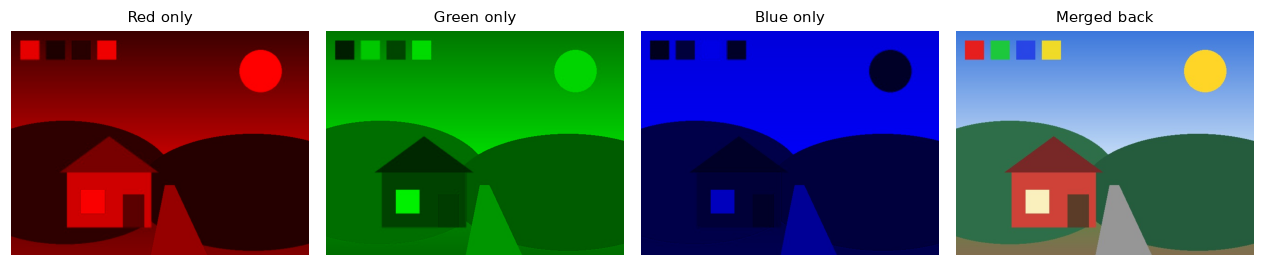

In [56]:
# Show each channel in its own colour, then merge back
zero = np.zeros_like(b)
show([bgr2rgb(cv2.merge([zero, zero, r])),
      bgr2rgb(cv2.merge([zero, g, zero])),
      bgr2rgb(cv2.merge([b, zero, zero])),
      bgr2rgb(cv2.merge([b, g, r]))],
     ["Red only", "Green only", "Blue only", "Merged back"], cols=4, size=2.9)

## 6. Geometric operations

### Resize
`cv2.resize(img, (width, height))` — note that the size is **(width, height)**, the opposite
order of `shape`. The `interpolation` argument decides how new pixels are guessed:

| flag | use it for |
|---|---|
| `INTER_NEAREST` | fastest, blocky, keeps label values exact |
| `INTER_LINEAR` | default, good for enlarging |
| `INTER_AREA` | best for shrinking |
| `INTER_CUBIC` | slower, sharper when enlarging |

small: (120, 160, 3) | half: (240, 320, 3)


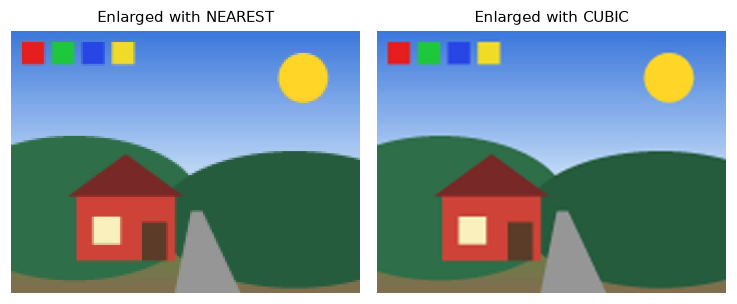

In [57]:
small = cv2.resize(img_bgr, (160, 120), interpolation=cv2.INTER_AREA)
half  = cv2.resize(img_bgr, None, fx=0.5, fy=0.5)          # by factor instead of size

big_nearest = cv2.resize(small, (480, 360), interpolation=cv2.INTER_NEAREST)
big_cubic   = cv2.resize(small, (480, 360), interpolation=cv2.INTER_CUBIC)

print("small:", small.shape, "| half:", half.shape)
show([bgr2rgb(big_nearest), bgr2rgb(big_cubic)],
     ["Enlarged with NEAREST", "Enlarged with CUBIC"])

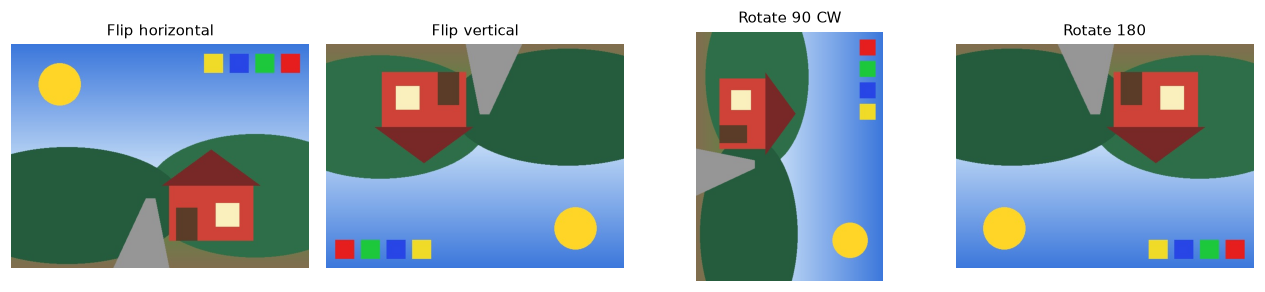

In [58]:
# Flip and 90-degree rotation (fast, no interpolation needed)
show([bgr2rgb(cv2.flip(img_bgr, 1)),
      bgr2rgb(cv2.flip(img_bgr, 0)),
      bgr2rgb(cv2.rotate(img_bgr, cv2.ROTATE_90_CLOCKWISE)),
      bgr2rgb(cv2.rotate(img_bgr, cv2.ROTATE_180))],
     ["Flip horizontal", "Flip vertical", "Rotate 90 CW", "Rotate 180"], cols=4, size=2.9)

### Translation and free rotation with `warpAffine`

Both are the same operation: multiply every pixel coordinate by a 2×3 matrix `M`.

* Translation: `M = [[1, 0, tx], [0, 1, ty]]`
* Rotation about a point: `cv2.getRotationMatrix2D(centre, angle, scale)`

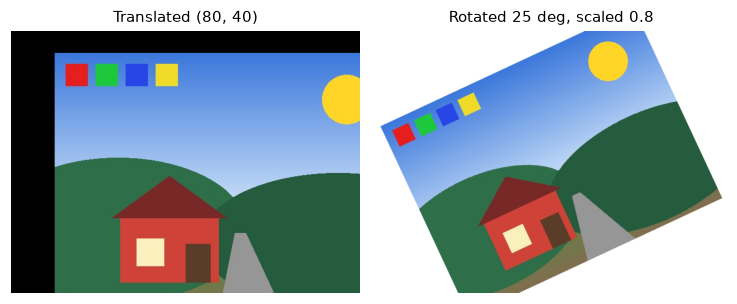

In [59]:
M_shift = np.float32([[1, 0, 80],       # 80 px right
                      [0, 1, 40]])      # 40 px down
shifted = cv2.warpAffine(img_bgr, M_shift, (w, h))

M_rot = cv2.getRotationMatrix2D((w / 2, h / 2), angle=25, scale=0.8)
rotated = cv2.warpAffine(img_bgr, M_rot, (w, h), borderValue=(255, 255, 255))

show([bgr2rgb(shifted), bgr2rgb(rotated)], ["Translated (80, 40)", "Rotated 25 deg, scaled 0.8"])

### Perspective warp

Four points in the source, four points in the destination. This is how a photo of a page taken
at an angle is flattened into a rectangle.

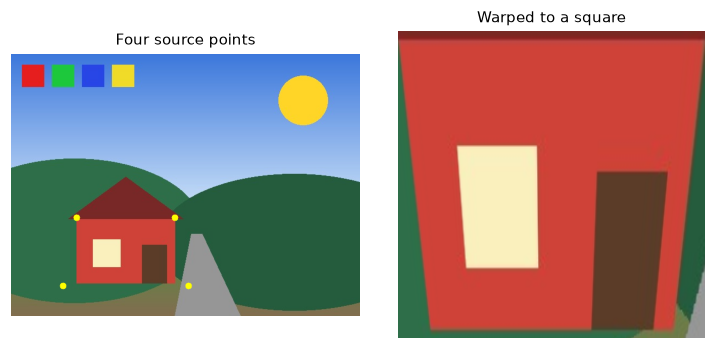

In [60]:
src = np.float32([[120, 300], [300, 300], [95, 425], [325, 425]])   # around the house
dst = np.float32([[0, 0], [300, 0], [0, 300], [300, 300]])

M_p = cv2.getPerspectiveTransform(src, dst)
warped = cv2.warpPerspective(img_bgr, M_p, (300, 300))

marked = img_bgr.copy()
for (x, y) in src.astype(int):
    cv2.circle(marked, (x, y), 6, (0, 255, 255), -1)

show([bgr2rgb(marked), bgr2rgb(warped)], ["Four source points", "Warped to a square"])

## 7. Arithmetic, blending and masks

`cv2.add` **saturates**: 250 + 10 = 255. NumPy `+` **wraps around**: 250 + 10 = 4, which turns
bright areas black. This is one of the most common bugs in a first lab.

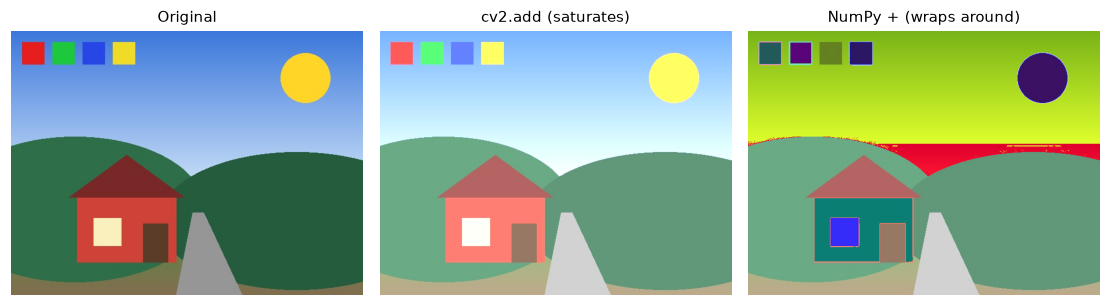

In [61]:
val = np.full_like(img_bgr, 60)

safe = cv2.add(img_bgr, val)        # clipped at 255
wrap = img_bgr + val                # wraps around -> ugly dark patches

show([bgr2rgb(img_bgr), bgr2rgb(safe), bgr2rgb(wrap)],
     ["Original", "cv2.add (saturates)", "NumPy + (wraps around)"])

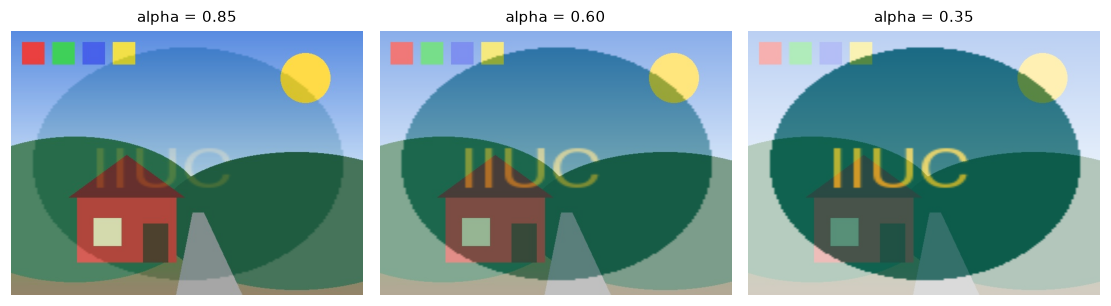

In [62]:
# Blending: dst = alpha*img1 + beta*img2 + gamma
logo = cv2.imread(str(IMG_DIR / "logo.png"))
logo_big = cv2.resize(logo, (w, h))

blends = [cv2.addWeighted(img_bgr, a, logo_big, 1 - a, 0) for a in (0.85, 0.6, 0.35)]
show([bgr2rgb(x) for x in blends],
     ["alpha = 0.85", "alpha = 0.60", "alpha = 0.35"])

### Putting a logo on the image with bitwise operations

Standard recipe: build a mask of the logo, cut a hole in the background with the inverse mask,
keep only the logo through the mask, then add the two.

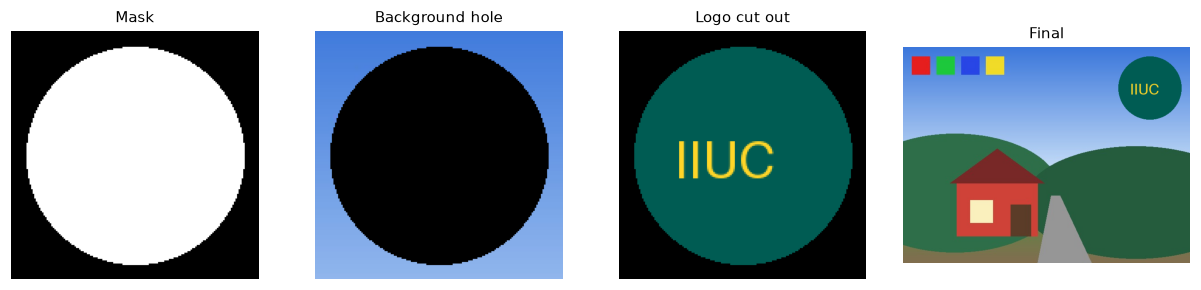

In [63]:
lh, lw = logo.shape[:2]
logo_roi = img_bgr[10:10 + lh, w - lw - 10:w - 10]

logo_gray = cv2.cvtColor(logo, cv2.COLOR_BGR2GRAY)
_, mask = cv2.threshold(logo_gray, 240, 255, cv2.THRESH_BINARY_INV)   # logo = white
mask_inv = cv2.bitwise_not(mask)

bg = cv2.bitwise_and(logo_roi, logo_roi, mask=mask_inv)   # background with a logo-shaped hole
fg = cv2.bitwise_and(logo, logo, mask=mask)          # logo without its white square

result = img_bgr.copy()
result[10:10 + lh, w - lw - 10:w - 10] = cv2.add(bg, fg)

show([mask, bgr2rgb(bg), bgr2rgb(fg), bgr2rgb(result)],
     ["Mask", "Background hole", "Logo cut out", "Final"], cols=4, size=2.8)

## 8. Drawing and text

Useful for marking detections later in the course. All of these draw **in place**, so work on a
copy. Colours are BGR. Thickness `-1` fills the shape.

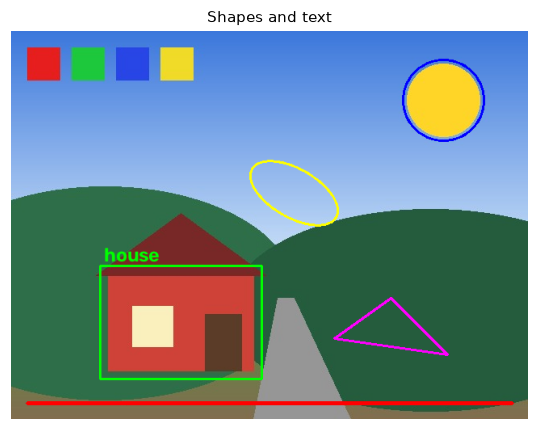

In [64]:
canvas = img_bgr.copy()
cv2.line(canvas, (20, 460), (620, 460), (0, 0, 255), 3)
cv2.rectangle(canvas, (110, 290), (310, 430), (0, 255, 0), 2)
cv2.circle(canvas, (535, 85), 50, (255, 0, 0), 2)
cv2.ellipse(canvas, (350, 200), (60, 30), 30, 0, 360, (0, 255, 255), 2)
cv2.polylines(canvas, [np.array([[400, 380], [470, 330], [540, 400]])], True, (255, 0, 255), 2)
cv2.putText(canvas, "house", (115, 285), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

show(bgr2rgb(canvas), ["Shapes and text"], size=5)

## 9. Thresholding

Thresholding turns a greyscale image into black and white.

* **Global**: one value for the whole image. Simple, fails when the light is uneven.
* **Otsu**: OpenCV picks the value automatically from the histogram.
* **Adaptive**: a different threshold for each small window. This is what you need for the
  page-under-a-lamp case.

Otsu chose threshold = 90.0


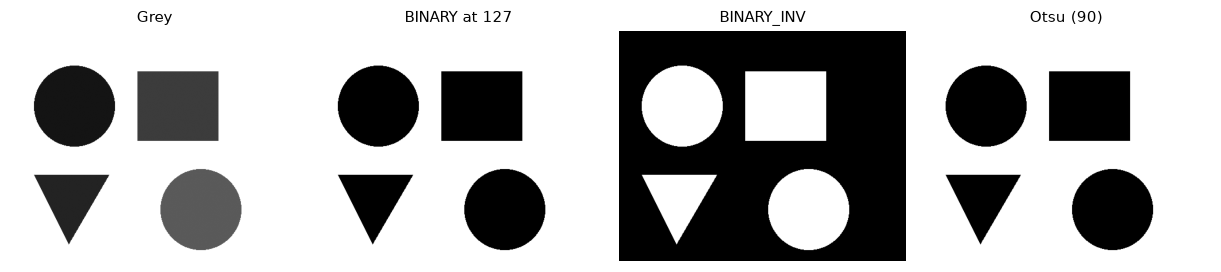

In [65]:
shapes = cv2.imread(str(IMG_DIR / "shapes.png"), cv2.IMREAD_GRAYSCALE)

_, binary = cv2.threshold(shapes, 127, 255, cv2.THRESH_BINARY)
_, inv    = cv2.threshold(shapes, 127, 255, cv2.THRESH_BINARY_INV)
t, otsu   = cv2.threshold(shapes, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print("Otsu chose threshold =", t)
show([shapes, binary, inv, otsu], ["Grey", "BINARY at 127", "BINARY_INV", f"Otsu ({t:.0f})"],
     cols=4, size=2.8)

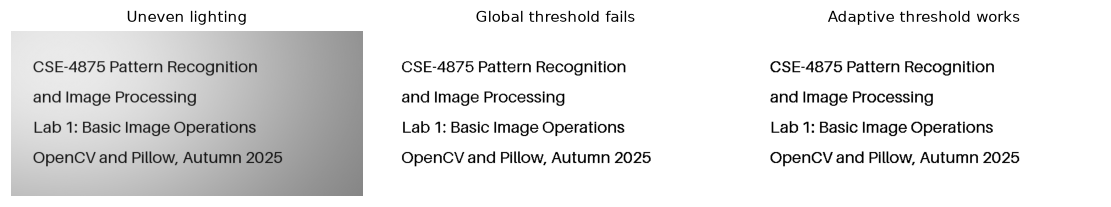

In [66]:
page = cv2.imread(str(IMG_DIR / "text.png"), cv2.IMREAD_GRAYSCALE)

_, global_t = cv2.threshold(page, 127, 255, cv2.THRESH_BINARY)
adaptive = cv2.adaptiveThreshold(page, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, blockSize=31, C=10)

show([page, global_t, adaptive],
     ["Uneven lighting", "Global threshold fails", "Adaptive threshold works"])

## 10. Histograms, equalisation and CLAHE

A histogram counts how many pixels have each intensity. A low-contrast image has all its
pixels squeezed into a narrow part of the range.

* `cv2.equalizeHist` spreads the values over the full 0–255 range.
* **CLAHE** does the same in small tiles with a contrast limit, so it does not blow up noise.

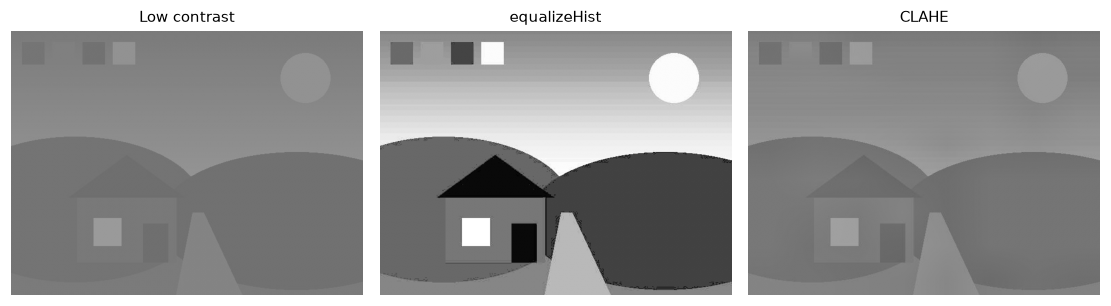

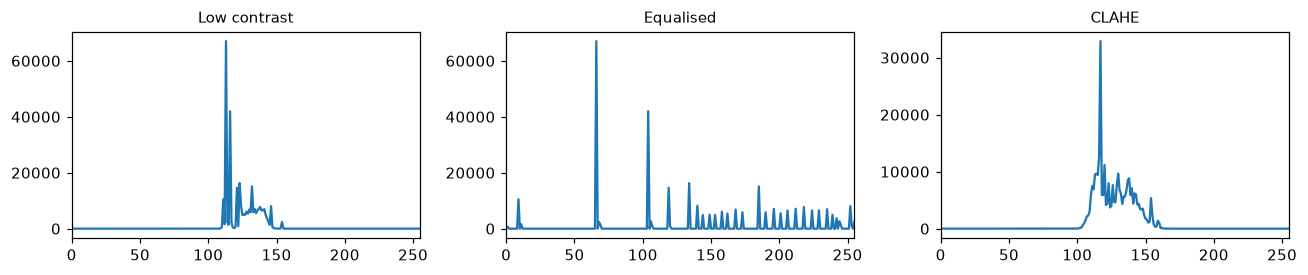

In [67]:
low = cv2.imread(str(IMG_DIR / "lowcontrast.jpg"), cv2.IMREAD_GRAYSCALE)
eq  = cv2.equalizeHist(low)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(low)

show([low, eq, clahe], ["Low contrast", "equalizeHist", "CLAHE"])

fig, axes = plt.subplots(1, 3, figsize=(12, 2.6))
for ax, im, t in zip(axes, [low, eq, clahe], ["Low contrast", "Equalised", "CLAHE"]):
    ax.plot(cv2.calcHist([im], [0], None, [256], [0, 256]))
    ax.set_title(t, fontsize=10); ax.set_xlim(0, 255)
plt.tight_layout(); plt.show()

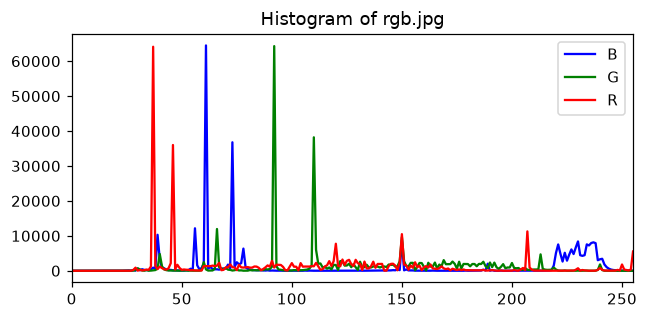

In [68]:
# Colour histogram: one curve per channel
plt.figure(figsize=(6, 3))
for i, col in enumerate(["b", "g", "r"]):
    plt.plot(cv2.calcHist([img_bgr], [i], None, [256], [0, 256]), color=col, label=col.upper())
plt.xlim(0, 255); plt.legend(); plt.title("Histogram of rgb.jpg"); plt.tight_layout(); plt.show()

## 11. Point transforms — the link to Lecture 3

These operate on one pixel at a time, and they come straight from the perception lecture.

* **Brightness and contrast**: `new = alpha*old + beta`.
* **Gamma correction**: `new = 255 * (old/255)**gamma`. Because subjective brightness is
  roughly logarithmic, a gamma below 1 lifts the dark areas where the eye is sensitive.
* **Quantisation**: reduce the number of grey levels and false contouring appears, exactly as
  predicted by the Weber ratio.

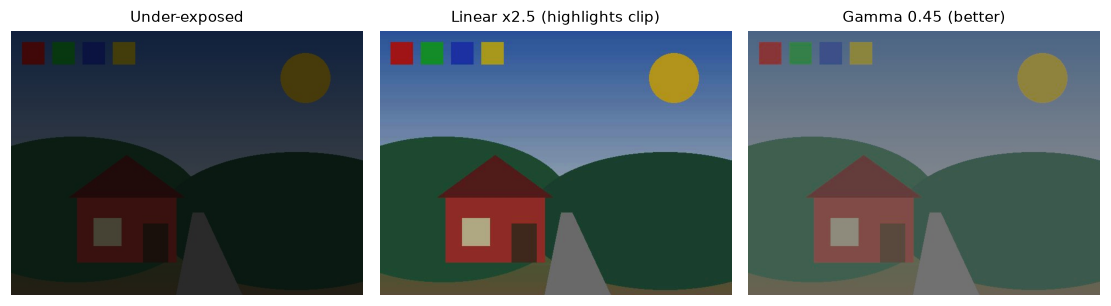

In [69]:
dark = cv2.imread(str(IMG_DIR / "dark.jpg"))

def gamma_correct(img, gamma):
    table = np.array([((i / 255.0) ** gamma) * 255 for i in range(256)]).astype("uint8")
    return cv2.LUT(img, table)            # LUT = look-up table, very fast

linear = cv2.convertScaleAbs(dark, alpha=2.5, beta=0)     # alpha*x + beta

show([bgr2rgb(dark), bgr2rgb(linear), bgr2rgb(gamma_correct(dark, 0.45))],
     ["Under-exposed", "Linear x2.5 (highlights clip)", "Gamma 0.45 (better)"])

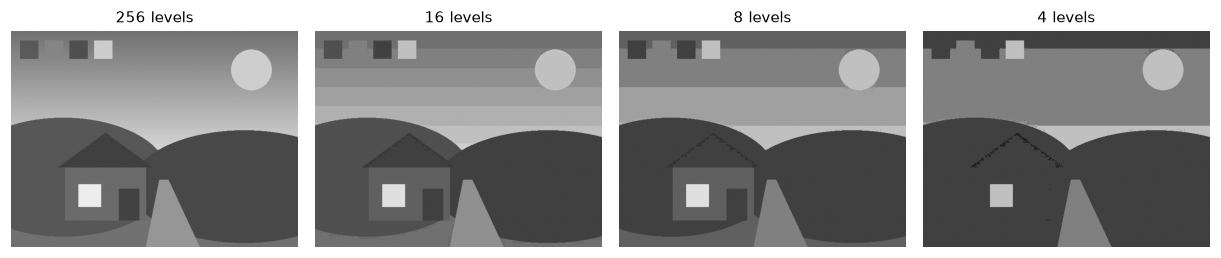

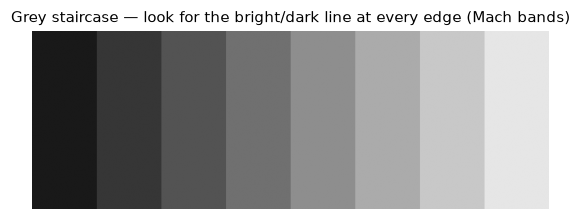

In [70]:
# False contouring: the claim from Lecture 2, now visible
ramp = cv2.imread(str(IMG_DIR / "gradient.png"), cv2.IMREAD_GRAYSCALE)
scene_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

def quantise(img, levels):
    step = 256 // levels
    return ((img // step) * step).astype(np.uint8)

show([scene_gray, quantise(scene_gray, 16), quantise(scene_gray, 8), quantise(scene_gray, 4)],
     ["256 levels", "16 levels", "8 levels", "4 levels"], cols=4, size=2.8)

show(ramp, ["Grey staircase — look for the bright/dark line at every edge (Mach bands)"], size=5)

## 12. Smoothing filters

A filter replaces each pixel by a function of its neighbours. Kernel size must be **odd**.

| filter | what it does | good for |
|---|---|---|
| `blur` | plain average | quick, blurs edges |
| `GaussianBlur` | weighted average | general noise reduction |
| `medianBlur` | middle value of the window | salt-and-pepper noise |
| `bilateralFilter` | averages only similar pixels | smooth, but keeps edges |

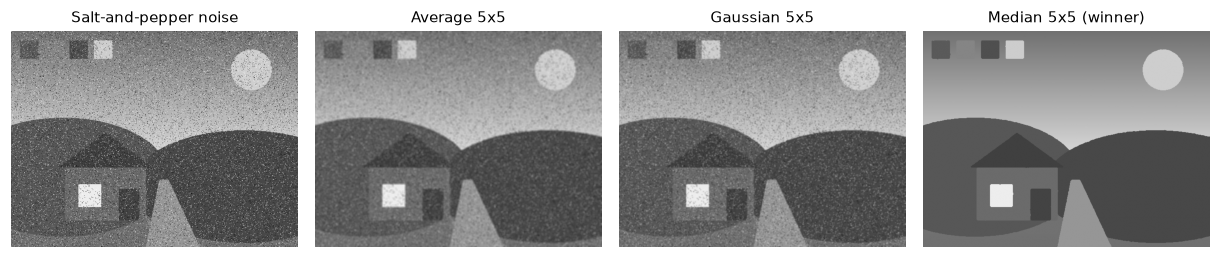

In [71]:
noisy = cv2.imread(str(IMG_DIR / "noisy.png"), cv2.IMREAD_GRAYSCALE)

show([noisy,
      cv2.blur(noisy, (5, 5)),
      cv2.GaussianBlur(noisy, (5, 5), 0),
      cv2.medianBlur(noisy, 5)],
     ["Salt-and-pepper noise", "Average 5x5", "Gaussian 5x5", "Median 5x5 (winner)"],
     cols=4, size=2.8)

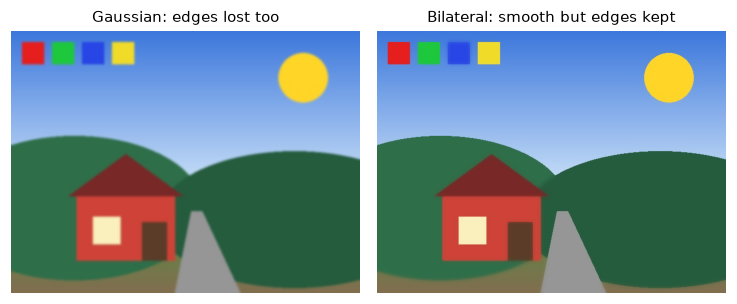

In [72]:
show([bgr2rgb(cv2.GaussianBlur(img_bgr, (11, 11), 0)),
      bgr2rgb(cv2.bilateralFilter(img_bgr, 15, 80, 80))],
     ["Gaussian: edges lost too", "Bilateral: smooth but edges kept"])

## 13. Sharpening and edges

Lecture 3 said the retina already enhances edges through lateral inhibition. These filters do
the same job with a kernel.

* `filter2D` with a custom kernel — sharpening.
* `Sobel` — first derivative, gives the gradient in x or y.
* `Laplacian` — second derivative, responds to all edges.
* `Canny` — the practical edge detector: smooth, gradient, thin, then two thresholds.

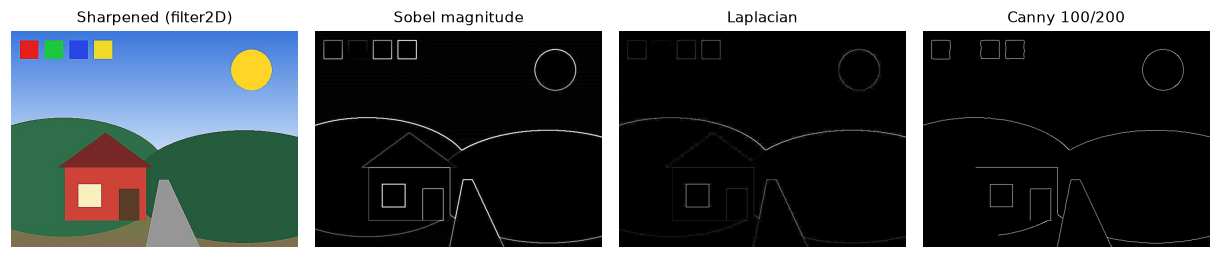

In [73]:
kernel = np.array([[ 0, -1,  0],
                   [-1,  5, -1],
                   [ 0, -1,  0]])
sharp = cv2.filter2D(img_bgr, -1, kernel)

sx = cv2.Sobel(scene_gray, cv2.CV_64F, 1, 0, ksize=3)
sy = cv2.Sobel(scene_gray, cv2.CV_64F, 0, 1, ksize=3)
mag = cv2.convertScaleAbs(np.hypot(sx, sy))
lap = cv2.convertScaleAbs(cv2.Laplacian(scene_gray, cv2.CV_64F))
canny = cv2.Canny(scene_gray, 100, 200)

show([bgr2rgb(sharp), mag, lap, canny],
     ["Sharpened (filter2D)", "Sobel magnitude", "Laplacian", "Canny 100/200"], cols=4, size=2.8)

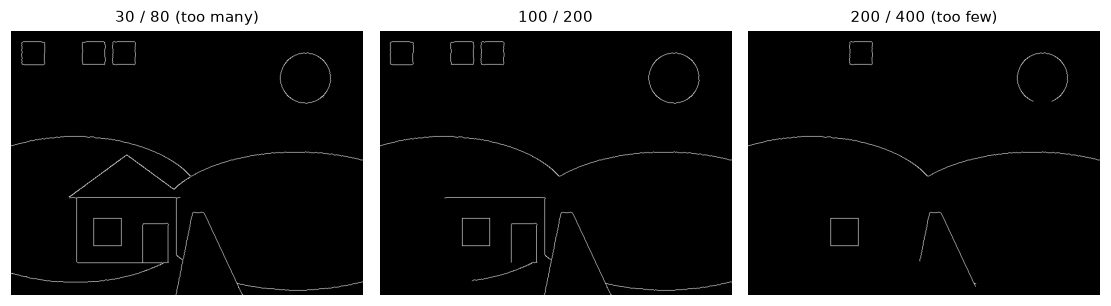

In [74]:
# Canny is sensitive to its two thresholds - change them and watch
show([cv2.Canny(scene_gray, 30, 80), cv2.Canny(scene_gray, 100, 200), cv2.Canny(scene_gray, 200, 400)],
     ["30 / 80 (too many)", "100 / 200", "200 / 400 (too few)"])

## 14. Bonus: finding and counting objects

Threshold → `findContours` → measure. Four lines of code and the lab already looks like real
computer vision.

objects found: 4


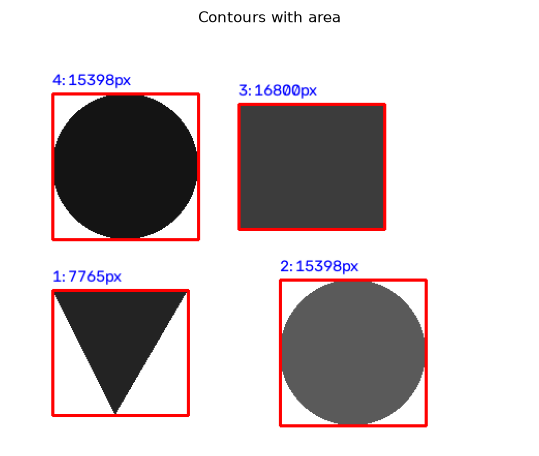

In [75]:
_, bw = cv2.threshold(shapes, 200, 255, cv2.THRESH_BINARY_INV)
contours, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

out = cv2.cvtColor(shapes, cv2.COLOR_GRAY2BGR)
print("objects found:", len(contours))
for i, cnt in enumerate(contours, 1):
    x, y, cw, ch = cv2.boundingRect(cnt)
    cv2.rectangle(out, (x, y), (x + cw, y + ch), (0, 0, 255), 2)
    cv2.putText(out, f"{i}: {int(cv2.contourArea(cnt))}px", (x, y - 8),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)

show(bgr2rgb(out), ["Contours with area"], size=5)

## 15. Pillow (PIL)

Pillow is the other common library. Compared with OpenCV:

| | OpenCV | Pillow |
|---|---|---|
| image object | NumPy array | `Image` object |
| channel order | **BGR** | **RGB** |
| strength | algorithms, speed, video | file formats, text, simple editing |
| resize | `cv2.resize(img, (w, h))` | `im.resize((w, h))` |

format: JPEG | size (w, h): (640, 480) | mode: RGB
thumbnail size: (160, 120)


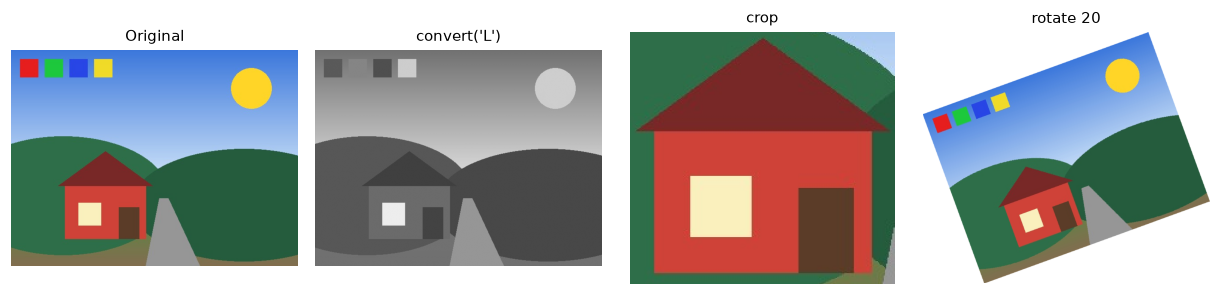

In [76]:
pim = Image.open(IMG_DIR / "rgb.jpg")
print("format:", pim.format, "| size (w, h):", pim.size, "| mode:", pim.mode)

gray_pil = pim.convert("L")
crop_pil = pim.crop((100, 220, 320, 430))          # (left, upper, right, lower)
rot_pil  = pim.rotate(20, expand=True, fillcolor=(255, 255, 255))

thumb = pim.copy()
thumb.thumbnail((160, 160))                        # keeps the aspect ratio, in place
print("thumbnail size:", thumb.size)

show([pim, gray_pil, crop_pil, rot_pil], ["Original", "convert('L')", "crop", "rotate 20"],
     cols=4, size=2.8)

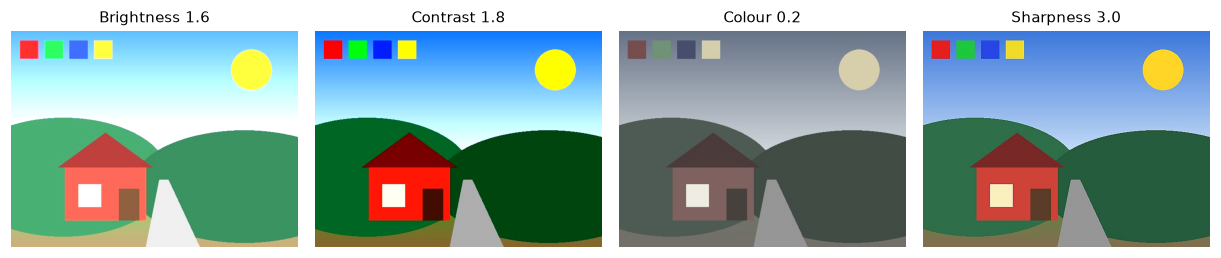

In [77]:
# ImageEnhance: brightness, contrast, colour, sharpness
show([ImageEnhance.Brightness(pim).enhance(1.6),
      ImageEnhance.Contrast(pim).enhance(1.8),
      ImageEnhance.Color(pim).enhance(0.2),
      ImageEnhance.Sharpness(pim).enhance(3.0)],
     ["Brightness 1.6", "Contrast 1.8", "Colour 0.2", "Sharpness 3.0"], cols=4, size=2.8)

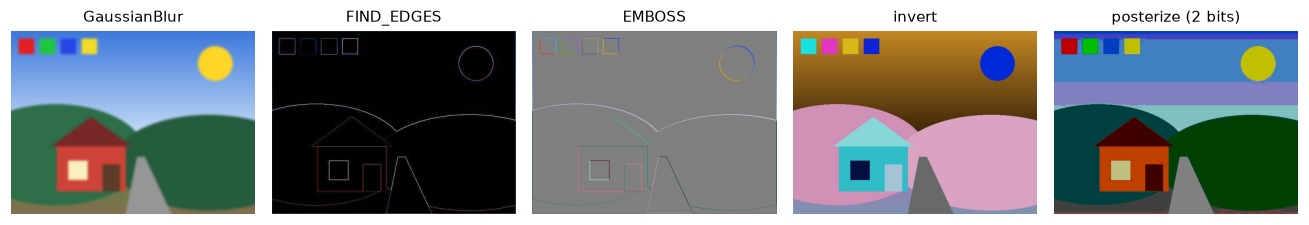

In [78]:
# ImageFilter and ImageOps
show([pim.filter(ImageFilter.GaussianBlur(3)),
      pim.filter(ImageFilter.FIND_EDGES),
      pim.filter(ImageFilter.EMBOSS),
      ImageOps.invert(pim),
      ImageOps.posterize(pim, 2)],
     ["GaussianBlur", "FIND_EDGES", "EMBOSS", "invert", "posterize (2 bits)"], cols=5, size=2.4)

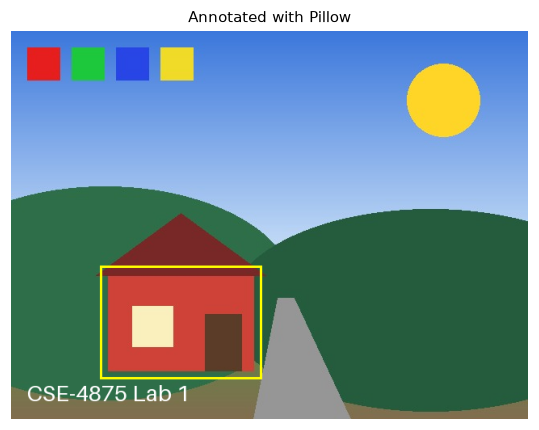

In [79]:
# Text and shapes with ImageDraw
draw_img = pim.copy()
d = ImageDraw.Draw(draw_img)
try:
    font = ImageFont.load_default(size=28)
except TypeError:
    font = ImageFont.load_default()
d.rectangle([110, 290, 310, 430], outline=(255, 255, 0), width=3)
d.text((20, 430), "CSE-4875 Lab 1", fill=(255, 255, 255), font=font)

draw_img.save(out_dir / "pillow_annotated.png")
show(draw_img, ["Annotated with Pillow"], size=5)

## 16. Moving between Pillow and OpenCV

You will need this constantly, because the two libraries disagree about channel order.

PIL -> cv2 : <class 'numpy.ndarray'> (480, 640, 3)
cv2 -> PIL : <class 'PIL.Image.Image'> (640, 480)
same pixels: True


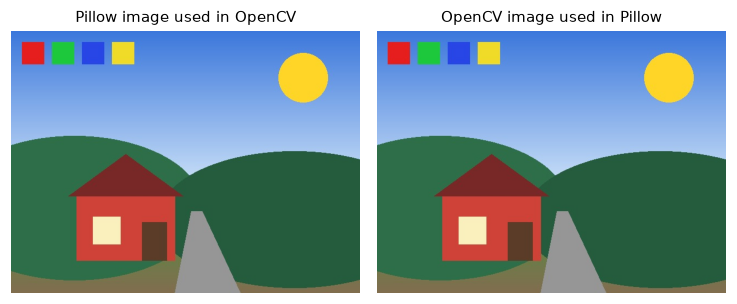

In [80]:
# Pillow -> OpenCV
pil_to_cv = cv2.cvtColor(np.array(pim), cv2.COLOR_RGB2BGR)

# OpenCV -> Pillow
cv_to_pil = Image.fromarray(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))

print("PIL -> cv2 :", type(pil_to_cv), pil_to_cv.shape)
print("cv2 -> PIL :", type(cv_to_pil), cv_to_pil.size)
print("same pixels:", np.array_equal(pil_to_cv, img_bgr))

show([bgr2rgb(pil_to_cv), cv_to_pil], ["Pillow image used in OpenCV", "OpenCV image used in Pillow"])

## 17. Batch processing a folder

The practical reason to learn all of this: doing the same job to 500 files without opening any
of them by hand.

In [81]:
batch_dir = out_dir / "batch"
batch_dir.mkdir(exist_ok=True)

for f in sorted(IMG_DIR.glob("*.jpg")) + sorted(IMG_DIR.glob("*.png")):
    im = cv2.imread(str(f))
    if im is None:
        print("skipped:", f.name); continue
    im = cv2.resize(im, (256, 256), interpolation=cv2.INTER_AREA)
    im = cv2.cvtColor(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), cv2.COLOR_GRAY2BGR)
    cv2.imwrite(str(batch_dir / f"{f.stem}_256_gray.png"), im)
    print(f"{f.name:18s} -> {f.stem}_256_gray.png")

print("\nfiles written:", len(list(batch_dir.glob('*'))))

dark.jpg           -> dark_256_gray.png
lowcontrast.jpg    -> lowcontrast_256_gray.png
rgb.jpg            -> rgb_256_gray.png
gradient.png       -> gradient_256_gray.png
logo.png           -> logo_256_gray.png
noisy.png          -> noisy_256_gray.png
shapes.png         -> shapes_256_gray.png
text.png           -> text_256_gray.png

files written: 8


## 18. Only on your own machine: `cv2.imshow` and the webcam

These two cells do **not** work in Colab. They work in VS Code because you have a real desktop.

A window opened by `cv2.imshow` stays until you press a key, and the notebook waits. If the
window ever freezes, run `cv2.destroyAllWindows()`.

In [82]:
# Uncomment to run. Click the window and press any key to close it.
# cv2.imshow("Lab 1 - press any key", img_bgr)
# cv2.waitKey(0)
# cv2.destroyAllWindows()

In [83]:
# Live webcam with a Canny edge view. Press q to quit.
# cap = cv2.VideoCapture(0)
# while True:
#     ok, frame = cap.read()
#     if not ok:
#         break
#     edges = cv2.Canny(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), 100, 200)
#     cv2.imshow("camera", frame)
#     cv2.imshow("edges", edges)
#     if cv2.waitKey(1) & 0xFF == ord("q"):
#         break
# cap.release()
# cv2.destroyAllWindows()

## 19. Common mistakes — keep this list

1. `cv2.imread` returned `None`. The path is wrong; it does not raise an error.
2. Colours look wrong → you forgot `cv2.COLOR_BGR2RGB` before `plt.imshow`.
3. `img.shape` is `(height, width)` but `cv2.resize` takes `(width, height)`.
4. `img[y, x]`, not `img[x, y]`.
5. `img + 60` wraps around at 255. Use `cv2.add` or `cv2.convertScaleAbs`.
6. Kernel sizes must be odd: `(5, 5)`, not `(4, 4)`.
7. Drawing functions change the image in place. Work on `img.copy()`.
8. A slice is a view. Changing it changes the original.

## 20. Tasks for today

**Task 1 — reading and properties (5 marks)**
Load one of your own photos. Print height, width, channels, dtype and the mean of each
channel. Show it correctly in RGB.

**Task 2 — colour selection (10 marks)**
Using HSV and `cv2.inRange`, select only the red house in `rgb.jpg`. Report the hue range you
used and the number of selected pixels. Red is split across both ends of the hue circle, so you
will need two ranges added together.

**Task 3 — the perception link (10 marks)**
Take `gradient.png`. Quantise `rgb.jpg` to 32, 16, 8 and 4 grey levels, and say at which level
false contouring first becomes visible to you. Explain the answer using the Weber ratio from
Lecture 3.

**Task 4 — a small pipeline (15 marks)**
Write one function `process(path)` that reads an image, converts to grey, removes noise,
detects edges with Canny and saves the result into `output/`. Run it over every file in
`images/` in a loop, and show the results in a 2×4 grid.

Submit the notebook with all outputs visible, exported as PDF.